# Figure 8 sideplot

Plot meridional distance versus the zonally-symmetric wind stress perturbation

Maximum of the perturbation bump: 0.037 N/m^2


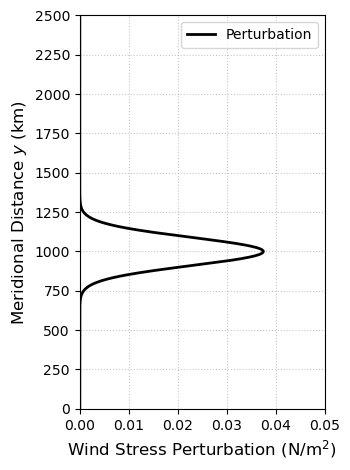

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Setup: Define necessary variables and functions ---

# # These variables were not in your snippet, so I've defined them based on your plot.
# # Adjust these values to match your specific model setup.
Ly = 2500 * 1e3  # Domain height in meters (2500 km)
yy = np.linspace(0, Ly, 1000) # Y-coordinate array in meters
Ln = 100e3 # length of northern sponge layer <--update with the appropriate values
Ys = 300e3 # location of shelf break <--update with the appropriate values
tau_east_max=0.15#0.2
# tau_west_max=0.05
# Y_tau0=Ly*0.2 # latitude where tau=0

# Gaussian function to create the bump
def gaussian(x, mu, sig):
    """Generates a gaussian bump centered at mu with width sig."""
    return np.exp(-np.power((x - mu) / sig, 2.0) / 2)

# --- 2. Calculation: Create the wind stress perturbation ---

# Parameters for the gaussian bump
mu = 1000  # Center of the bump in km
sig = 90   # Standard deviation (width) of the bump in km

# Calculate the bump. We use yy/1e3 to work with kilometers.
bump = gaussian(yy / 1e3, mu, sig)

# Scale the bump to a physical wind stress value (25% of tau_east_max)
bump = bump * tau_east_max / 4

print(f"Maximum of the perturbation bump: {np.max(bump):.3f} N/m^2")

# --- 3. Plotting: Visualize the result ---

fz = 12 # Font size

# Create a single plot figure and axes
fig, ax = plt.subplots(figsize=(3*1.2, 4*1.2))

# Plot the wind stress perturbation
ax.plot(bump, yy / 1e3, label='Perturbation', color='black', linewidth=2)

# Add reference lines for context
# ax.axvline(0, linestyle='-', linewidth=1.5, color='k')
# ax.axhline(Ys / 1e3, linestyle='--', linewidth=1.5, color='0.5', label='Shelf Break')

# Set labels and title for clarity
ax.set_xlabel("Wind Stress Perturbation (N/m$^2$)", fontsize=fz)
ax.set_ylabel("Meridional Distance $y$ (km)", fontsize=fz)
# ax.set_title("Wind Stress Perturbation", fontsize=fz + 2, weight='bold')

# Set limits and ticks
ax.set_xlim(-0, 0.05) # Tightened limits for a cleaner look
ax.set_ylim(0, Ly / 1e3)
ax.set_yticks(np.arange(0, 2501, 250))

# Add a grid and a legend
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='best', fontsize=fz - 2)

# Ensure everything fits nicely
plt.tight_layout()

# --- 4. Save and Show: Output the file and display the plot ---

# Save the figure to a file. dpi=300 is good for presentations/papers.
plt.savefig(f"wind_perturbation_profile_yc_{int(mu)}km.jpg", dpi=300, bbox_inches='tight')

# Display the plot in the notebook
plt.show()